# Building a constrained hedge

This native Julia companion preserves the public sample, formulas, optimization rules and original random seeds. Fixed initialization uniforms reproduce the public K-means candidates; Julia computes every candidate, silhouette score, cluster and allocation. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

A symmetric covariance matrix has an orthonormal eigenvector basis in which portfolio variance is a weighted sum of squared component exposures:

$$
\Sigma=V\Lambda V^{\mathsf T},
\qquad
w^{\mathsf T}\Sigma w=\sum_{k=1}^{N}\lambda_k z_k^2,
\qquad
z=V^{\mathsf T}w.
$$

Here, $\Sigma$ is the covariance matrix for $N$ assets, $V$ contains $N$ orthonormal eigenvectors, $\Lambda$ is diagonal with eigenvalues $\lambda_k$, $k$ labels a component from $1$ through $N$, $w$ is an asset-weight vector, and $z_k$ is its exposure to principal component $k$.

Row,Field,Value
,String,String
1,Provider,Kenneth R. French Data Library
2,Return type,Daily value-weighted return
3,Analysis start,2019-01-02
4,Analysis end,2025-12-31
5,Complete dates,1760
6,Selected industries,16
7,Selection rule,"First 16 industries in archive order, fixed before analysis"


Row,Component,Eigenvalue,Explained variance share,Cumulative variance share
,Int64,Float64,Float64,Float64
1,1,0.595064,0.565847,0.565847
2,2,0.0937926,0.0891875,0.655035
3,3,0.0774768,0.0736728,0.728707
4,4,0.0520957,0.0495379,0.778245
5,5,0.042011,0.0399483,0.818194
6,6,0.0333566,0.0317188,0.849912
7,7,0.0327067,0.0311008,0.881013
8,8,0.0248089,0.0235909,0.904604
9,9,0.0221243,0.021038,0.925642


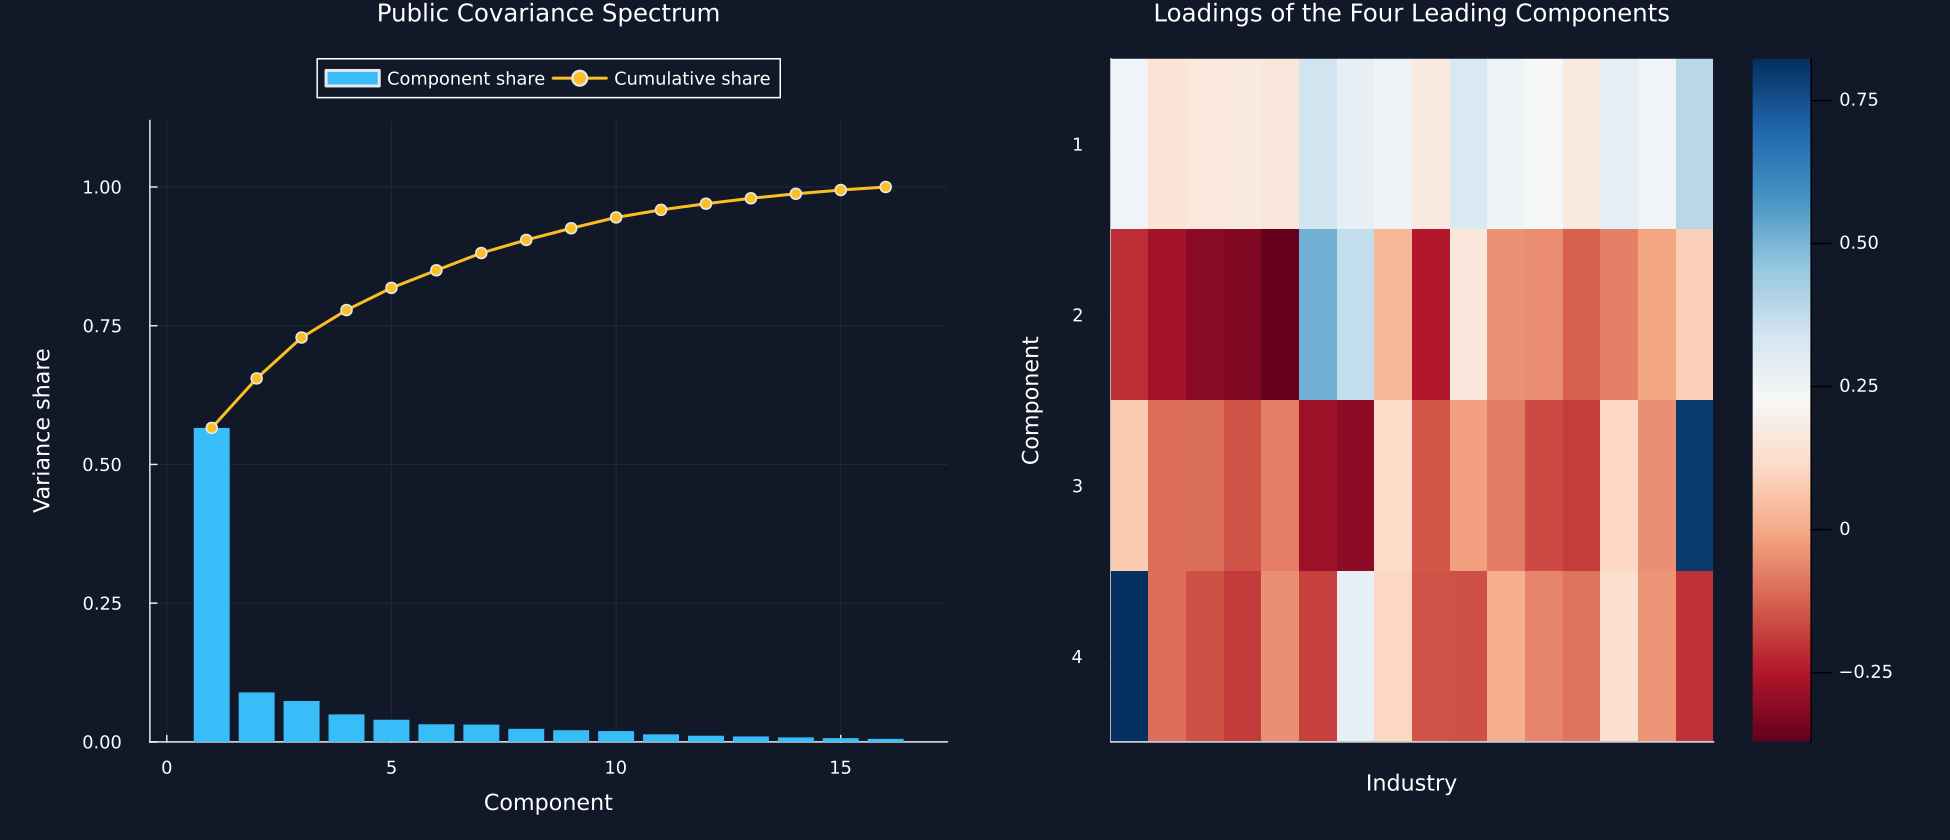

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("26_nested_cluster_optimization");
using CSV, TOML, Printf
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
include(joinpath("..","support","BookHierarchy.jl"))
using .BookHierarchy
using RiskLabAI.Optimization: cluster_variance,hrp,inverse_variance_weights,recursive_bisection
violet = "#C084FC"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter21-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
dates = all_dates[valid]
selected_assets = names(raw)[2:17]
public_sample = all_values[valid,1:16]/100
annual_covariance,public_correlation = cov(public_sample)*252,cor(public_sample)
function matrix_panel(values,labels,title;limits=nothing,color=:magma)
    n = length(labels)
    return heatmap(1:n,1:n,values;title,color,clims=isnothing(limits) ? extrema(values) : limits,yflip=true,xticks=(1:n,labels),yticks=(1:n,labels),xrotation=90,tickfontsize=7,xlims=(0.5,n+0.5),ylims=(0.5,n+0.5),widen=false)
end
function tree_panel(tree,order,labels,title)
    n = length(labels)
    positions,heights = zeros(2n-1),zeros(2n-1)
    positions[order] = 1:n
    figure = plot(;title,xlim=(0.3,n+0.7),ylim=(0,1.08*maximum(tree[:,3])),xticks=(1:n,labels[order]),xrotation=90,tickfontsize=7,ylabel="Merge distance",legend=false)
    for step in axes(tree,1)
        left,right = Int.(tree[step,1:2]).+1
        height = tree[step,3]
        plot!(figure,[positions[left],positions[left],positions[right],positions[right]],[heights[left],height,height,heights[right]];color=palette.cyan)
        positions[n+step],heights[n+step] = (positions[left]+positions[right])/2,height
    end
    return figure
end
path_length(distance,order) = sum(distance[order[i],order[i+1]] for i in 1:length(order)-1)
turnover(a,b) = 0.5*sum(abs,a-b)
finite_mean(values) = mean(filter(isfinite,values))
include(joinpath("..","support","BookNCO.jl"))
using .BookNCO
using RiskLabAI.Optimization: get_optimal_portfolio_weights
selected_assets = ["Agriculture","Food products","Soft drinks","Beer and liquor","Tobacco","Recreation","Entertainment","Printing and publishing","Household products","Apparel","Health care","Medical equipment","Pharmaceutical products","Chemicals","Rubber and plastic products","Textiles"]
public_covariance = annual_covariance
random_root = joinpath("..","data","chapter26_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root,"inputs.toml"))["files"]
function primitive(name)
    path = joinpath(random_root,name)
    return Matrix{Float64}(CSV.read(path,DataFrame))
end
public_provenance = DataFrame("Field"=>["Provider","Return type","Analysis start","Analysis end","Complete dates","Selected industries","Selection rule"],"Value"=>["Kenneth R. French Data Library","Daily value-weighted return",string(first(dates)),string(last(dates)),string(length(dates)),"16","First 16 industries in archive order, fixed before analysis"])
using RiskLabAI.Optimization: pca_weights
factor = eigen(Symmetric(public_covariance,:L);alg=LinearAlgebra.DivideAndConquer())
order = sortperm(factor.values;rev=true)
eigenvalues = factor.values[order]
eigenvectors = factor.vectors[:,order]
for component in axes(eigenvectors,2)
    anchor = argmax(abs.(eigenvectors[:,component]))
    if eigenvectors[anchor,component]<0
        eigenvectors[:,component] .*= -1
    end
end
explained_variance = eigenvalues/sum(eigenvalues)
cumulative_variance = cumsum(explained_variance)
spectrum_table = DataFrame("Component"=>1:16,"Eigenvalue"=>eigenvalues,"Explained variance share"=>explained_variance,"Cumulative variance share"=>cumulative_variance)
table(public_provenance,"hedge_data_provenance","Public data used for the Chapter 22 hedge calculations.")
table(spectrum_table,"public_pca_spectrum","Principal-component spectrum of the public industry covariance matrix.")
p1 = bar(1:16,explained_variance;color=palette.cyan,linealpha=0,label="Component share",title="Public Covariance Spectrum",xlabel="Component",ylabel="Variance share",ylims=(0,1.12),legend=:outertop,legend_columns=2)
plot!(p1,1:16,cumulative_variance;color=palette.amber,marker=:circle,label="Cumulative share")
p2 = heatmap(1:16,1:4,eigenvectors[:,1:4]';color=:RdBu,yflip=true,xticks=false,yticks=1:4,xlabel="Industry",ylabel="Component",title="Loadings of the Four Leading Components")
save_figure(plot(p1,p2;layout=(1,2),size=(1300,560)),paths,"public_pca_spectrum_loadings")
save_data(DataFrame(eigenvectors,:auto),paths,"canonical_pca_vectors")
function weight_profile(baskets,colors,title;columns=1)
    figure = plot(;title,xlabel="Weight",yticks=(1:16,selected_assets),yflip=true,legend=:outertop,legend_columns=columns,left_margin=49Plots.mm,size=(1200,1050),legendfontsize=8)
    values = reduce(vcat,last.(baskets))
    lo,hi = extrema(values)
    for (offset,(name,weights)) in enumerate(baskets)
        bar!(figure,(1:16).+(offset-2)*0.24,weights;orientation=:h,bar_width=0.24,linealpha=0,color=colors[offset],label=name)
    end
    plot!(figure;xlims=(min(0,lo)-0.08*(hi-lo),max(0,hi)+0.08*(hi-lo)),ylims=(0.4,16.6))
    return figure
end
nothing


## Risk Targets in Principal Coordinates

A component-risk distribution produces asset weights by scaling each eigenvector inversely with the square root of its eigenvalue:

$$
w=V\left(s\sqrt{\rho_1/\lambda_1},\ldots,s\sqrt{\rho_N/\lambda_N}\right)^{\mathsf T},
\qquad
\rho_k\geq0,
\qquad
\sum_{k=1}^{N}\rho_k=1.
$$

Here, $s$ is the target portfolio standard deviation, $\rho_k$ is the target share of variance assigned to component $k$, $\lambda_k$ is that component's eigenvalue, $N$ is the number of assets and components, and $V$ maps component exposures back to asset weights. Each eigenvector is given a fixed orientation by making its largest absolute loading positive. This rule affects the signs of weights and net exposure, but not variance, gross exposure, or component-risk shares.

Row,Basket,Realized standard deviation,Net exposure,Gross exposure,Active components,Largest component variance share
,String,Float64,Float64,Float64,Int64,Float64
1,Leading component,0.1,0.496472,0.496472,1,1.0
2,Equal component risk,0.1,0.049346,2.13011,16,0.0625
3,Smallest component,0.1,0.174582,2.58518,1,1.0


Row,Basket,Industry,Weight
,String,String,Float64
1,Leading component,Agriculture,0.0323448
2,Leading component,Food products,0.0186026
3,Leading component,Soft drinks,0.0209191
4,Leading component,Beer and liquor,0.0215827
5,Leading component,Tobacco,0.0206769
6,Leading component,Recreation,0.0447381
7,Leading component,Entertainment,0.0359715
8,Leading component,Printing and publishing,0.0331036
9,Leading component,Household products,0.0217592


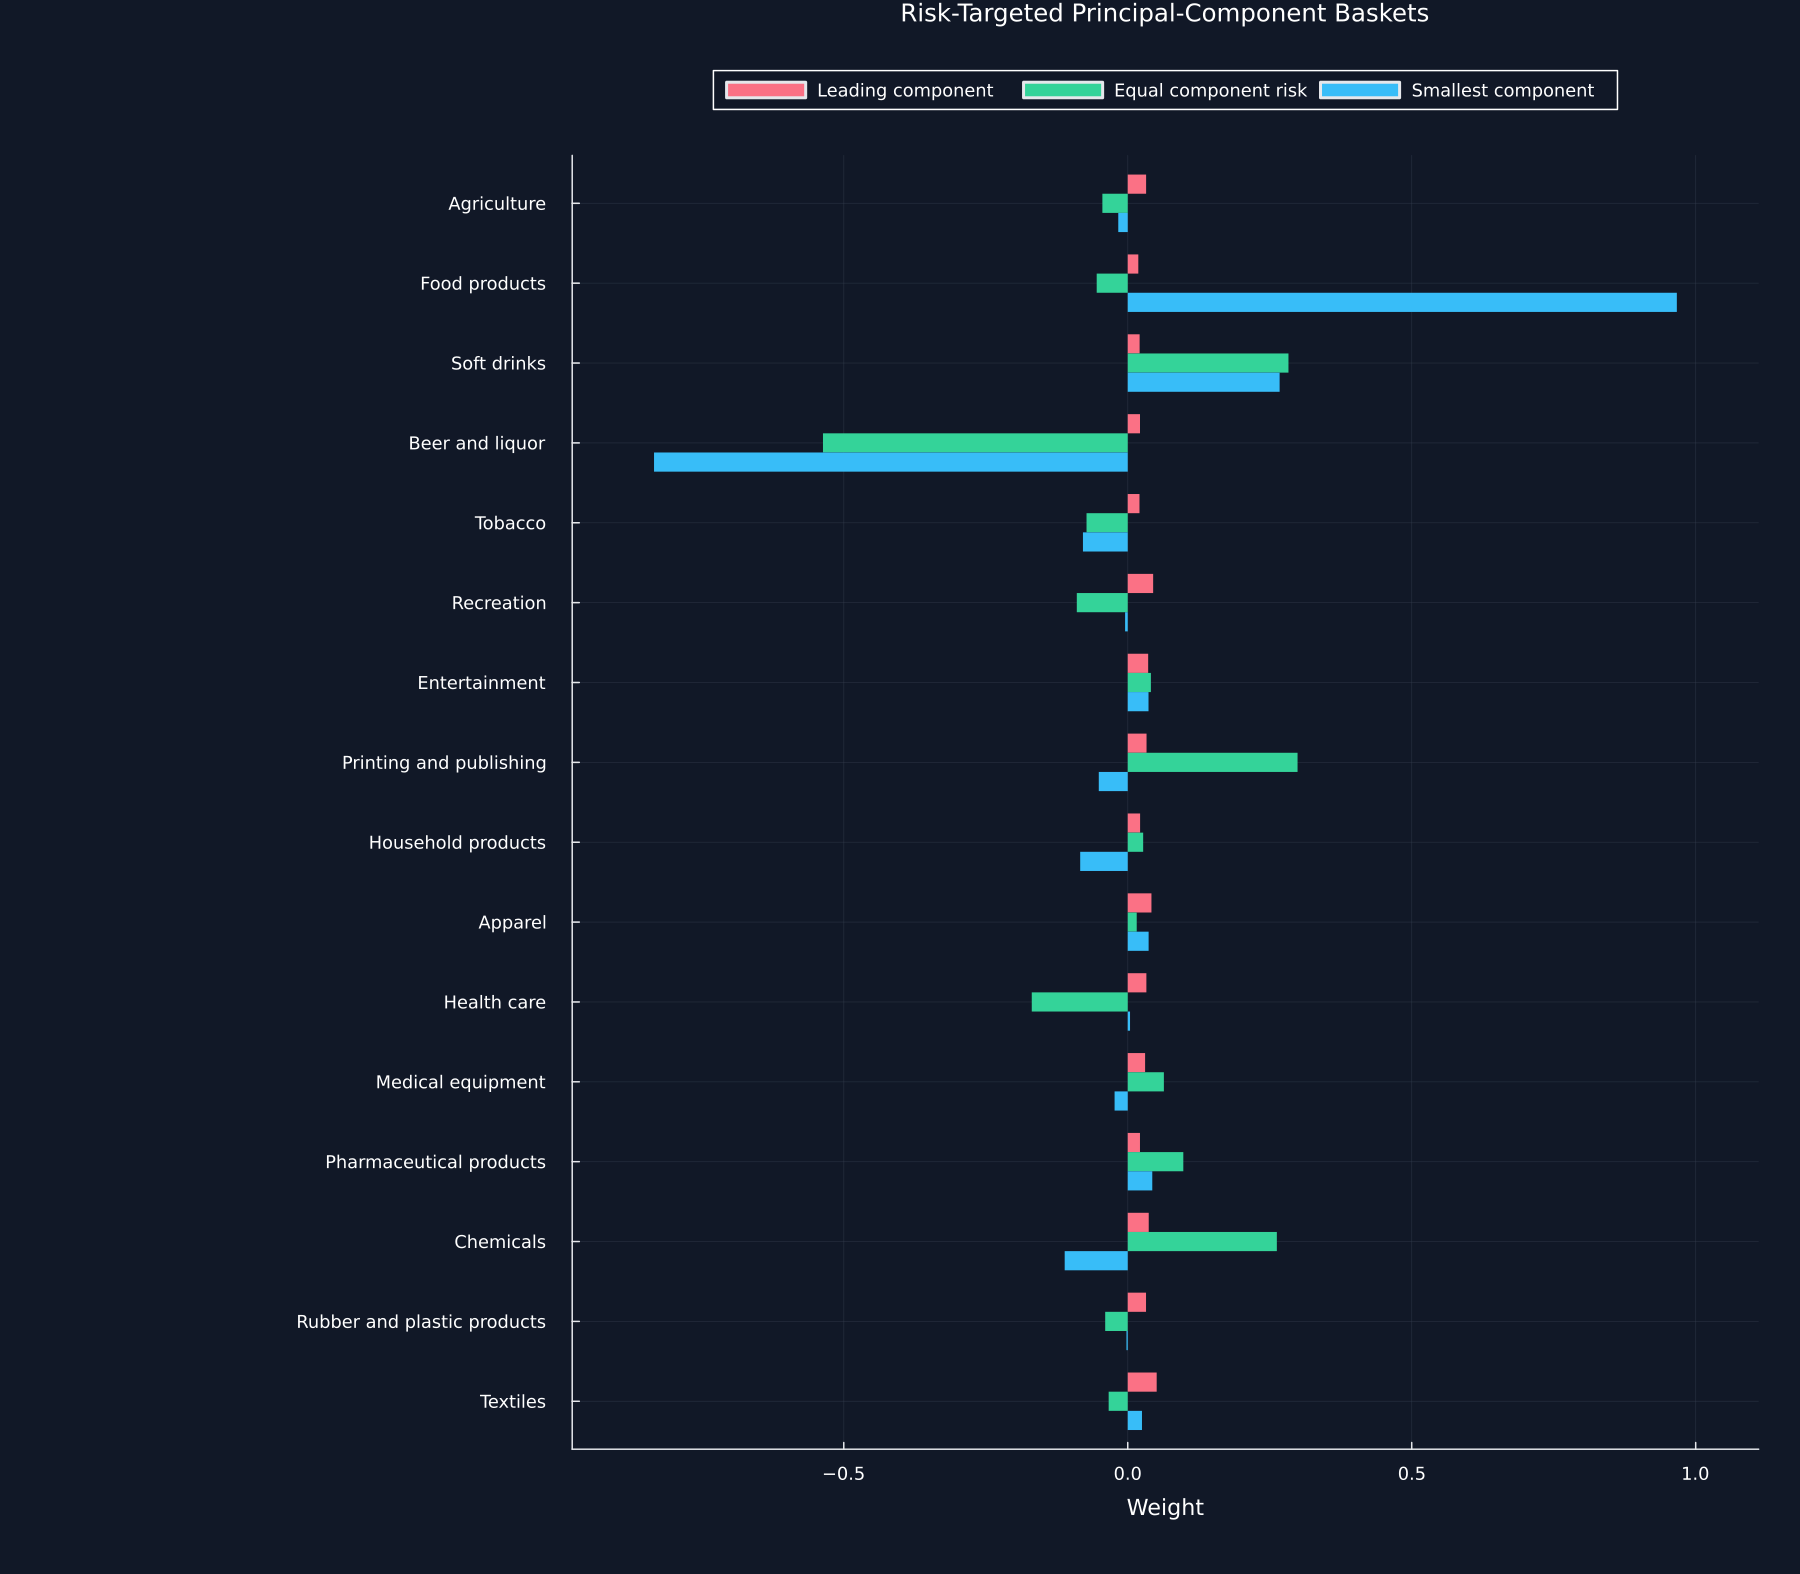

In [2]:
target_standard_deviation = 0.10
component_count = 16
risk_distributions = ["Leading component"=>vcat(1.0,zeros(15)),"Equal component risk"=>fill(1/16,16),"Smallest component"=>vcat(zeros(15),1.0)]
library_pca_baskets = [name=>pca_weights(public_covariance;risk_distribution=distribution,risk_target=target_standard_deviation) for (name,distribution) in risk_distributions]
pca_baskets = [name=>eigenvectors*(target_standard_deviation*sqrt.(distribution./eigenvalues)) for (name,distribution) in risk_distributions]
target_rows,weight_rows = NamedTuple[],NamedTuple[]
for (index,(name,weights)) in enumerate(pca_baskets)
    exposure = eigenvectors'*weights
    component_variance = eigenvalues.*exposure.^2
    append!(weight_rows,[(Basket=name,Industry=selected_assets[i],Weight=weights[i]) for i in 1:16])
    push!(target_rows,(Basket=name,volatility=sqrt(dot(weights,public_covariance*weights)),net=sum(weights),gross=sum(abs,weights),active=count(!iszero,last(risk_distributions[index])),largest=maximum(component_variance)/sum(component_variance)))
end
pca_target_summary = DataFrame(target_rows)
rename!(pca_target_summary,["Basket","Realized standard deviation","Net exposure","Gross exposure","Active components","Largest component variance share"])
pca_weight_table = DataFrame(weight_rows)
table(pca_target_summary,"pca_risk_target_summary","Risk targets and exposures for three principal-component baskets.")
table(pca_weight_table,"pca_weight_profiles","Asset weights for three principal-component risk distributions.")
save_figure(weight_profile(pca_baskets,[palette.rose,palette.green,palette.cyan],"Risk-Targeted Principal-Component Baskets";columns=3),paths,"pca_weight_profiles")


## Component Exposures

The share of portfolio variance assigned to component $k$ is obtained from its eigenvalue and component exposure:

$$
\operatorname{PCRS}_k=\frac{\lambda_k z_k^2}{\sum_{j=1}^{N}\lambda_j z_j^2}.
$$

Here, $z_k=v_k^{\mathsf T}w$ is exposure to eigenvector $v_k$, $\lambda_k$ is its eigenvalue, $j$ indexes every component in the denominator, $N$ is the number of components, and $\operatorname{PCRS}_k$ is the principal-component risk share.

Row,Basket,Component,Eigenvalue,Component exposure,Variance contribution,Variance share
,String,Int64,Float64,Float64,Float64,Float64
1,Leading component,1,0.595064,0.129634,0.01,1.0
2,Leading component,2,0.0937926,6.93889e-18,4.51595e-36,4.51595e-34
3,Leading component,3,0.0774768,3.46945e-18,9.32593e-37,9.32593e-35
4,Leading component,4,0.0520957,1.04083e-17,5.64372e-36,5.64372e-34
5,Leading component,5,0.042011,-6.93889e-18,2.02276e-36,2.02276e-34
6,Leading component,6,0.0333566,-3.46945e-18,4.01516e-37,4.01516e-35
7,Leading component,7,0.0327067,-1.73472e-18,9.8423e-38,9.8423e-36
8,Leading component,8,0.0248089,6.07153e-18,9.14545e-37,9.14545e-35
9,Leading component,9,0.0221243,-3.46945e-18,2.66312e-37,2.66312e-35


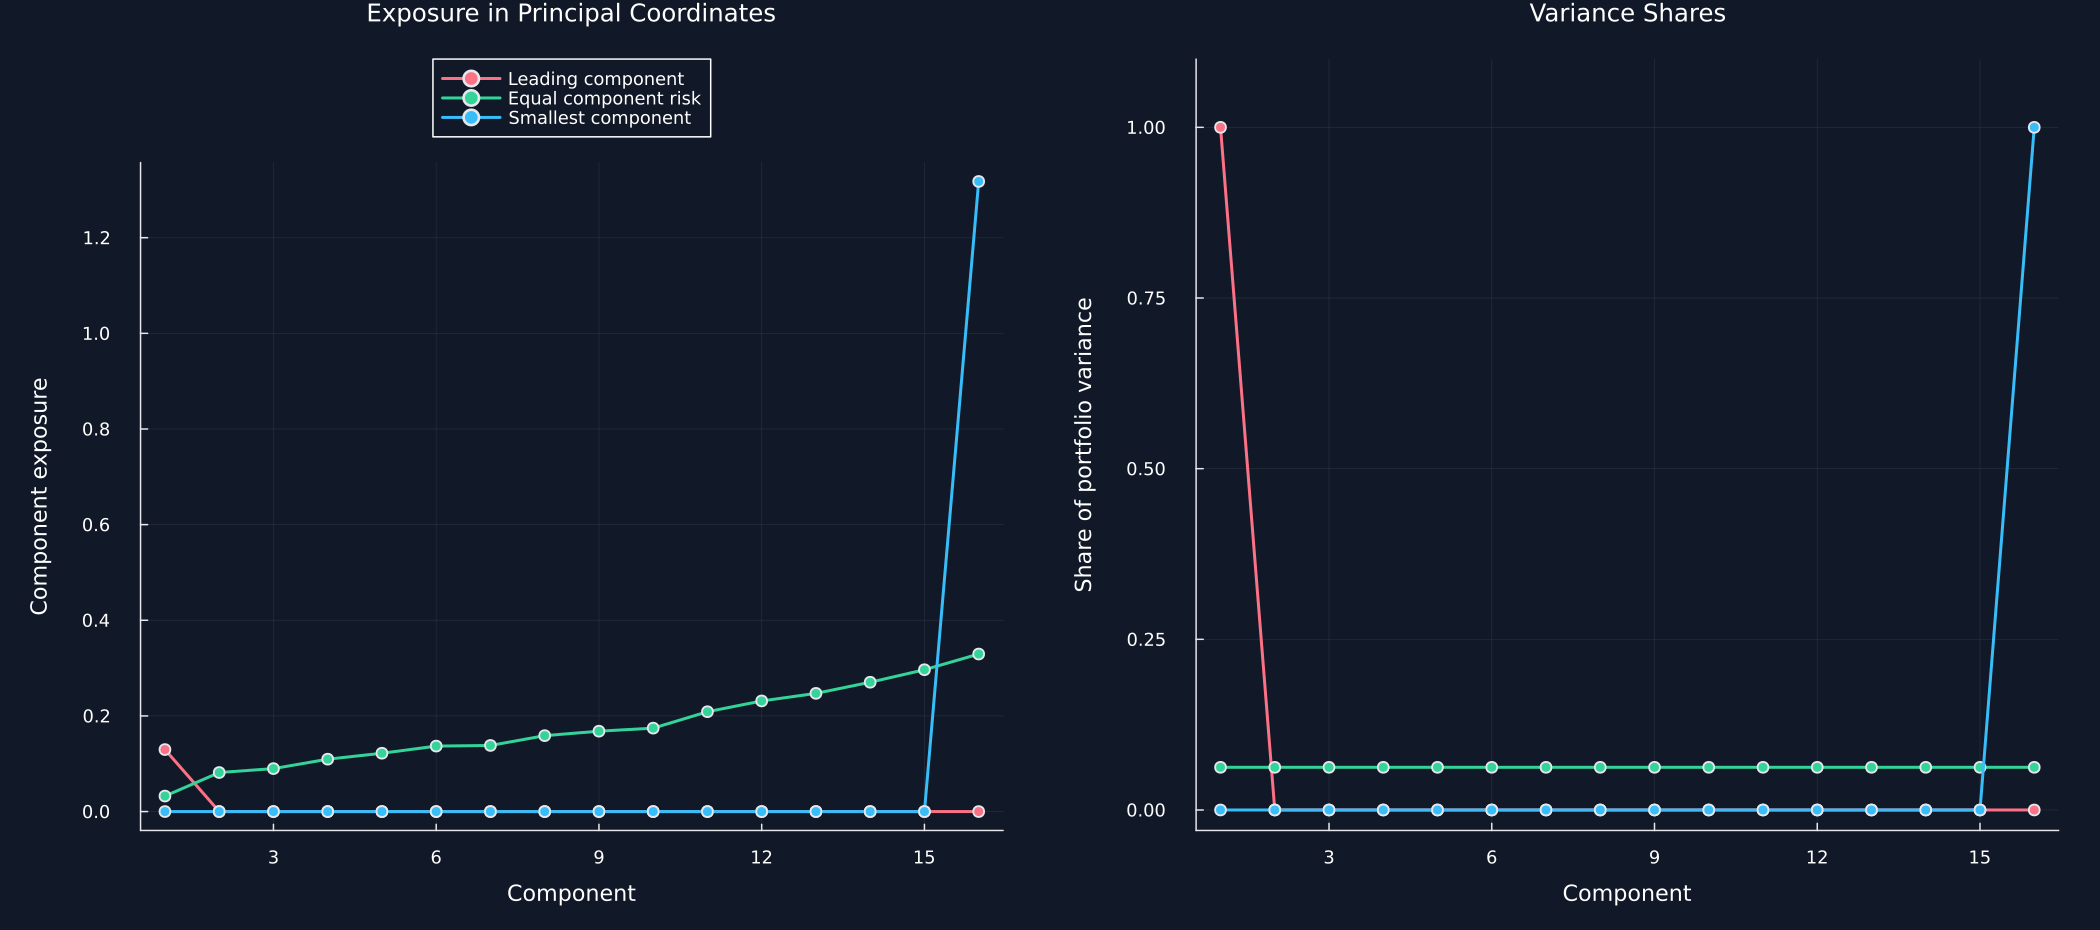

In [3]:
component_rows = NamedTuple[]
for (name,weights) in pca_baskets
    exposures = eigenvectors'*weights
    variances = eigenvalues.*exposures.^2
    append!(component_rows,[(Basket=name,Component=i,Eigenvalue=eigenvalues[i],exposure=exposures[i],contribution=variances[i],share=variances[i]/sum(variances)) for i in 1:16])
end
component_risk = DataFrame(component_rows)
rename!(component_risk,["Basket","Component","Eigenvalue","Component exposure","Variance contribution","Variance share"])
table(component_risk,"pca_component_risk","Principal-component exposures and variance shares.")
p1 = plot(;title="Exposure in Principal Coordinates",xlabel="Component",ylabel="Component exposure",legend=:outertop,legendfontsize=8)
p2 = plot(;title="Variance Shares",xlabel="Component",ylabel="Share of portfolio variance",legend=false,ylims=(-0.03,1.1))
for ((name,weights),color) in zip(pca_baskets,[palette.rose,palette.green,palette.cyan])
    subset = component_risk[component_risk.Basket.==name,:]
    plot!(p1,1:16,subset[!,"Component exposure"];color,marker=:circle,label=name)
    plot!(p2,1:16,subset[!,"Variance share"];color,marker=:circle)
end
save_figure(plot(p1,p2;layout=(1,2),size=(1400,620)),paths,"pca_component_exposures")


## Diagnosing hedge contributions

Asset-level variance contribution and correlation with the basket answer different exposure questions:

$$
\operatorname{RC}_i=w_i(\Sigma w)_i,
\qquad
\operatorname{Corr}(r_i,r_w)=\frac{(\Sigma w)_i}{\sqrt{\Sigma_{ii}}\sqrt{w^{\mathsf T}\Sigma w}}.
$$

Here, $w_i$ is the weight of asset $i$, $(\Sigma w)_i$ is its covariance with the basket, $\operatorname{RC}_i$ is its contribution to basket variance, $r_i$ is its return, and $r_w=w^{\mathsf T}r$ is the basket return.

Row,Basket,Annual volatility,Net exposure,Gross exposure,Largest absolute variance-contribution share,Largest absolute asset-to-basket correlation
,String,Float64,Float64,Float64,Float64,Float64
1,Equal weight,0.185824,1.0,1.0,0.0964896,0.888332
2,Minimum variance,0.147925,1.0,1.95891,0.489942,0.884732
3,Smallest-component gross one,0.0386821,0.0675321,1.0,0.538411,0.333073
4,Smallest-component dollar neutral,0.0400746,-1.04083e-17,1.0,0.716071,0.450654


Row,Basket,Industry,Weight,Variance contribution,Variance-contribution share,Correlation to basket
,String,String,Float64,Float64,Float64,Float64
1,Equal weight,Agriculture,0.0625,0.00225856,0.0654075,0.671892
2,Equal weight,Food products,0.0625,0.00139678,0.0404506,0.719311
3,Equal weight,Soft drinks,0.0625,0.00156777,0.0454023,0.705041
4,Equal weight,Beer and liquor,0.0625,0.00162657,0.0471053,0.709128
5,Equal weight,Tobacco,0.0625,0.00156399,0.045293,0.602662
6,Equal weight,Recreation,0.0625,0.00294644,0.0853283,0.725992
7,Equal weight,Entertainment,0.0625,0.00241487,0.0699341,0.677759
8,Equal weight,Printing and publishing,0.0625,0.0022534,0.0652579,0.787159
9,Equal weight,Household products,0.0625,0.00161154,0.04667,0.761285


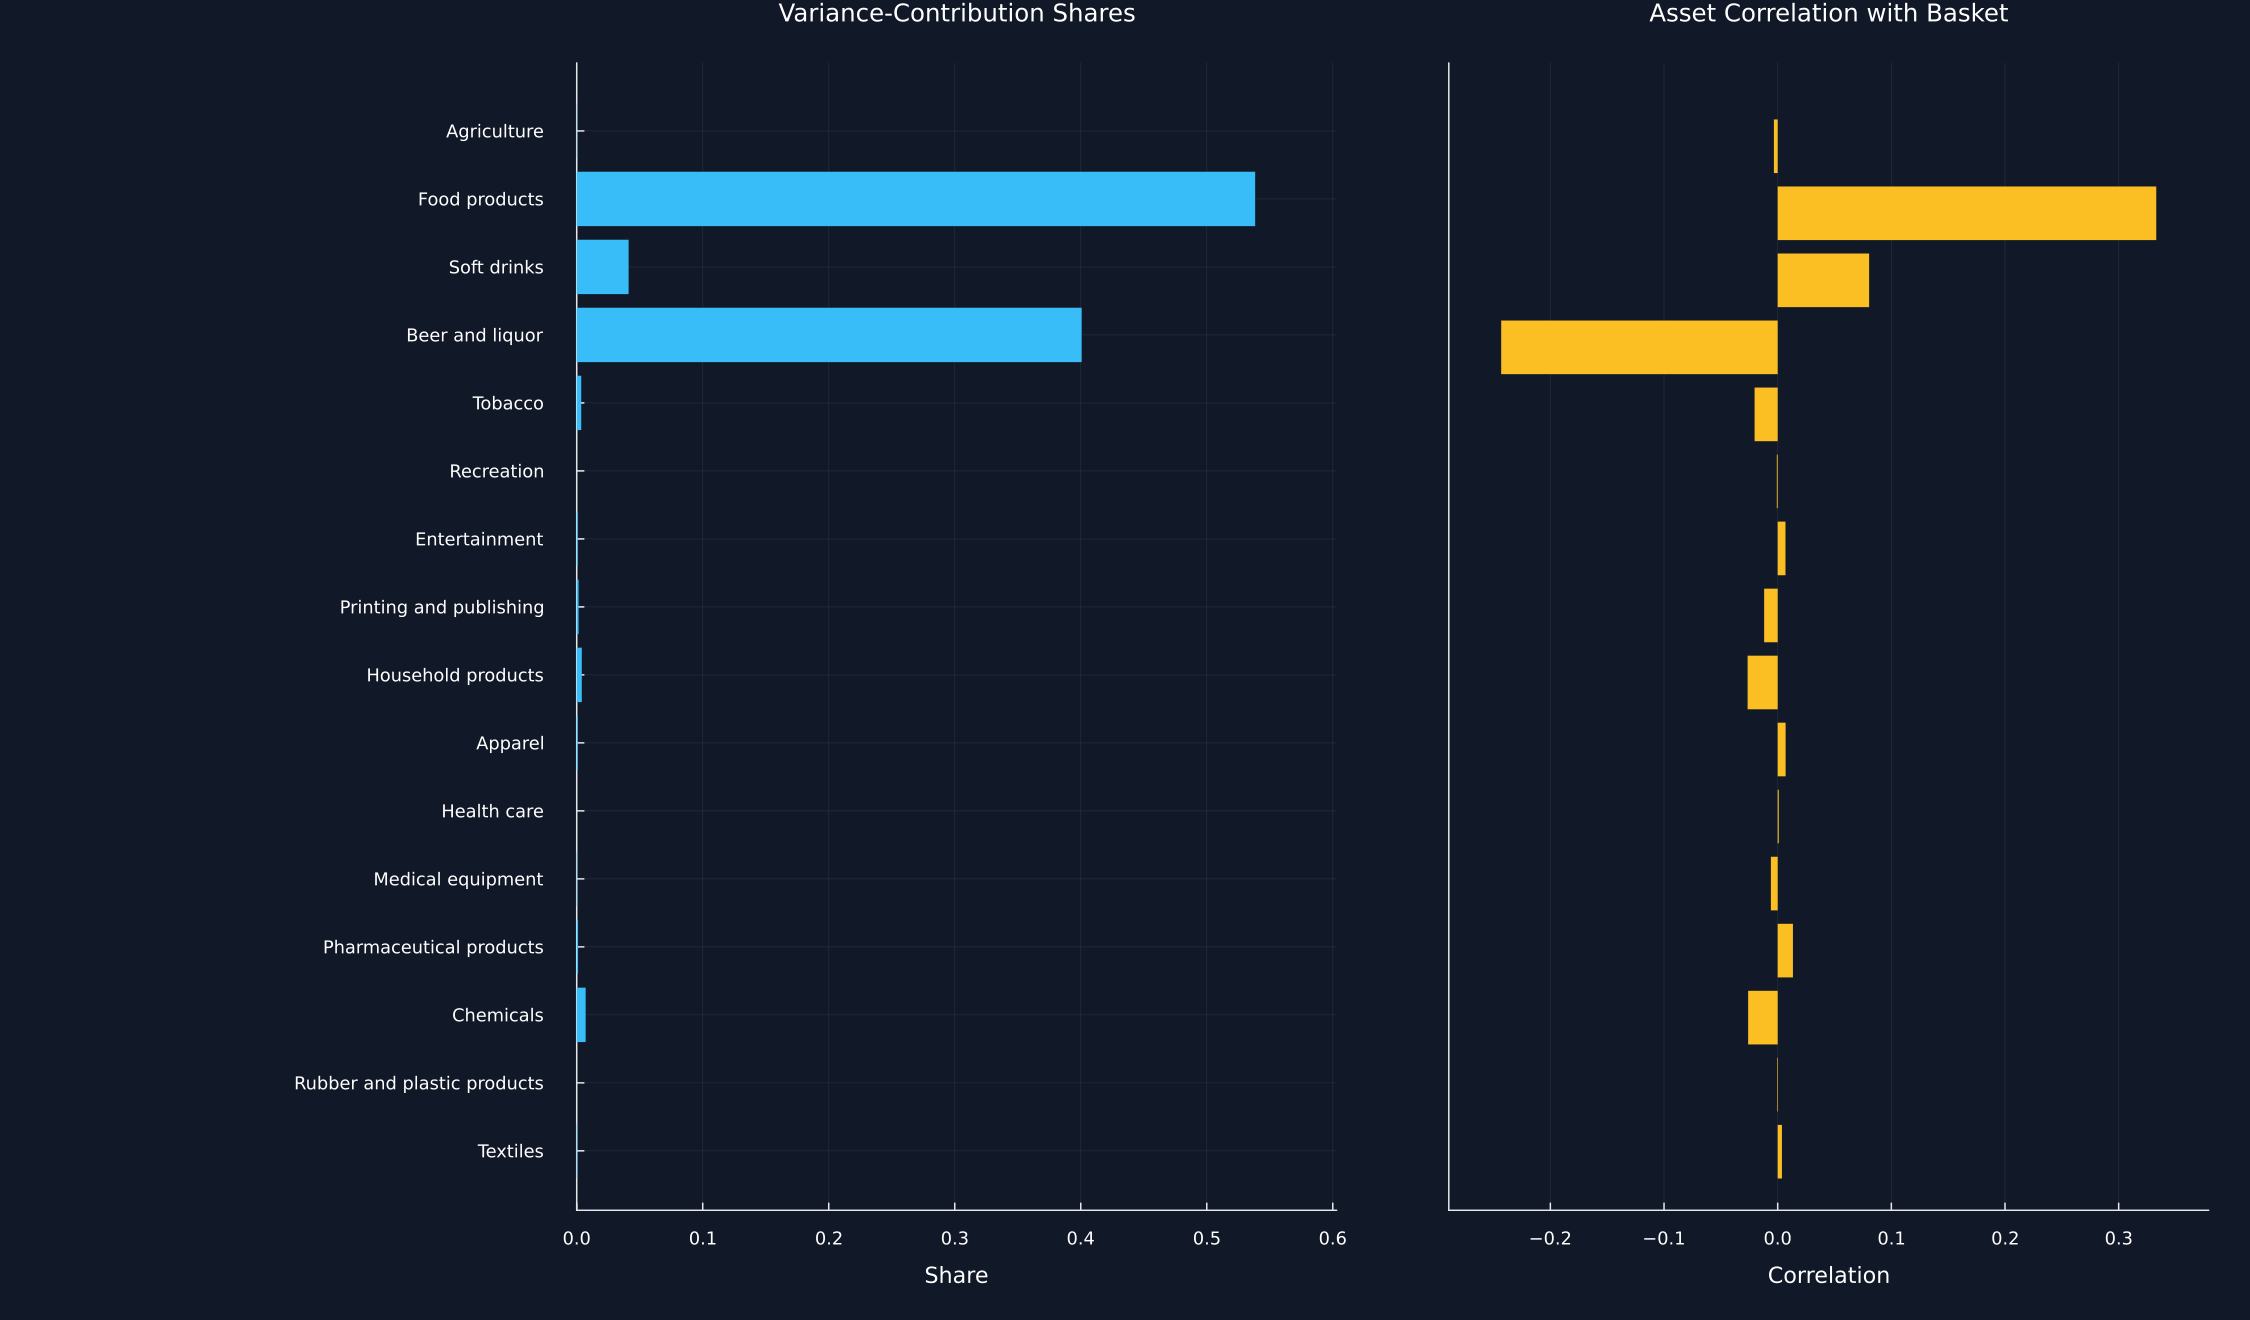

In [4]:
smallest_raw = last(pca_baskets[end])
smallest_gross = smallest_raw/sum(abs,smallest_raw)
neutral_values = smallest_gross.-mean(smallest_gross)
smallest_neutral = neutral_values/sum(abs,neutral_values)
diagnostic_baskets = ["Equal weight"=>fill(1/16,16),"Minimum variance"=>get_optimal_portfolio_weights(public_covariance),"Smallest-component gross one"=>smallest_gross,"Smallest-component dollar neutral"=>smallest_neutral]
diagnostic_rows,asset_rows = NamedTuple[],NamedTuple[]
asset_scales = sqrt.(diag(public_covariance))
for (name,weights) in diagnostic_baskets
    marginal = public_covariance*weights
    variance = dot(weights,marginal)
    contributions = weights.*marginal
    correlations = marginal./(asset_scales*sqrt(variance))
    push!(diagnostic_rows,(Basket=name,volatility=sqrt(variance),net=sum(weights),gross=sum(abs,weights),contribution=maximum(abs,contributions/variance),correlation=maximum(abs,correlations)))
    append!(asset_rows,[(Basket=name,Industry=selected_assets[i],Weight=weights[i],contribution=contributions[i],share=contributions[i]/variance,correlation=correlations[i]) for i in 1:16])
end
basket_diagnostics = DataFrame(diagnostic_rows)
rename!(basket_diagnostics,["Basket","Annual volatility","Net exposure","Gross exposure","Largest absolute variance-contribution share","Largest absolute asset-to-basket correlation"])
asset_diagnostics = DataFrame(asset_rows)
rename!(asset_diagnostics,["Basket","Industry","Weight","Variance contribution","Variance-contribution share","Correlation to basket"])
table(basket_diagnostics,"basket_exposure_diagnostics","Risk and correlation diagnostics for four public baskets.")
table(asset_diagnostics,"asset_exposure_diagnostics","Asset-level contribution and correlation diagnostics.")
subset = asset_diagnostics[asset_diagnostics.Basket.=="Smallest-component gross one",:]
p1 = bar(1:16,subset[!,"Variance-contribution share"];orientation=:h,yflip=true,yticks=(1:16,selected_assets),color=palette.cyan,linealpha=0,legend=false,title="Variance-Contribution Shares",xlabel="Share",left_margin=49Plots.mm,xlims=(0,1.12maximum(subset[!,"Variance-contribution share"])))
lo,hi = extrema(subset[!,"Correlation to basket"])
p2 = bar(1:16,subset[!,"Correlation to basket"];orientation=:h,yflip=true,yticks=false,color=palette.amber,linealpha=0,legend=false,title="Asset Correlation with Basket",xlabel="Correlation",xlims=(lo-0.08*(hi-lo),hi+0.08*(hi-lo)))
save_figure(plot(p1,p2;layout=(1,2),size=(1500,880)),paths,"basket_risk_and_correlation")


## Subset Exposure

The correlation between a subset return and the full basket can reveal concentration that individual weights do not show:

$$
\operatorname{Corr}(r_G,r_w)=\frac{u_G^{\mathsf T}\Sigma w}{\sqrt{u_G^{\mathsf T}\Sigma u_G}\sqrt{w^{\mathsf T}\Sigma w}}.
$$

Here, $G$ is a subset of assets, $r$ is the vector of asset returns, $u_G$ is an equal-weight vector supported only on that subset, $r_G=u_G^{\mathsf T}r$ is its return, $w$ is the full basket, $r_w=w^{\mathsf T}r$ is the basket return, and $\Sigma$ is the asset covariance matrix.

Row,Basket,Cluster,Industries,Subset correlation,Variance share
,String,Int64,Int64,Float64,Float64
1,Equal weight,1,10,0.97208,0.72974
2,Equal weight,2,6,0.83776,0.27026
3,Minimum variance,1,10,0.662756,-0.00243561
4,Minimum variance,2,6,0.925357,1.00244
5,Smallest-component dollar neutral,1,10,-0.302877,0.135543
6,Smallest-component dollar neutral,2,6,-0.242719,0.864457
7,Smallest-component gross one,1,10,-0.00274186,0.0110001
8,Smallest-component gross one,2,6,0.0168648,0.989


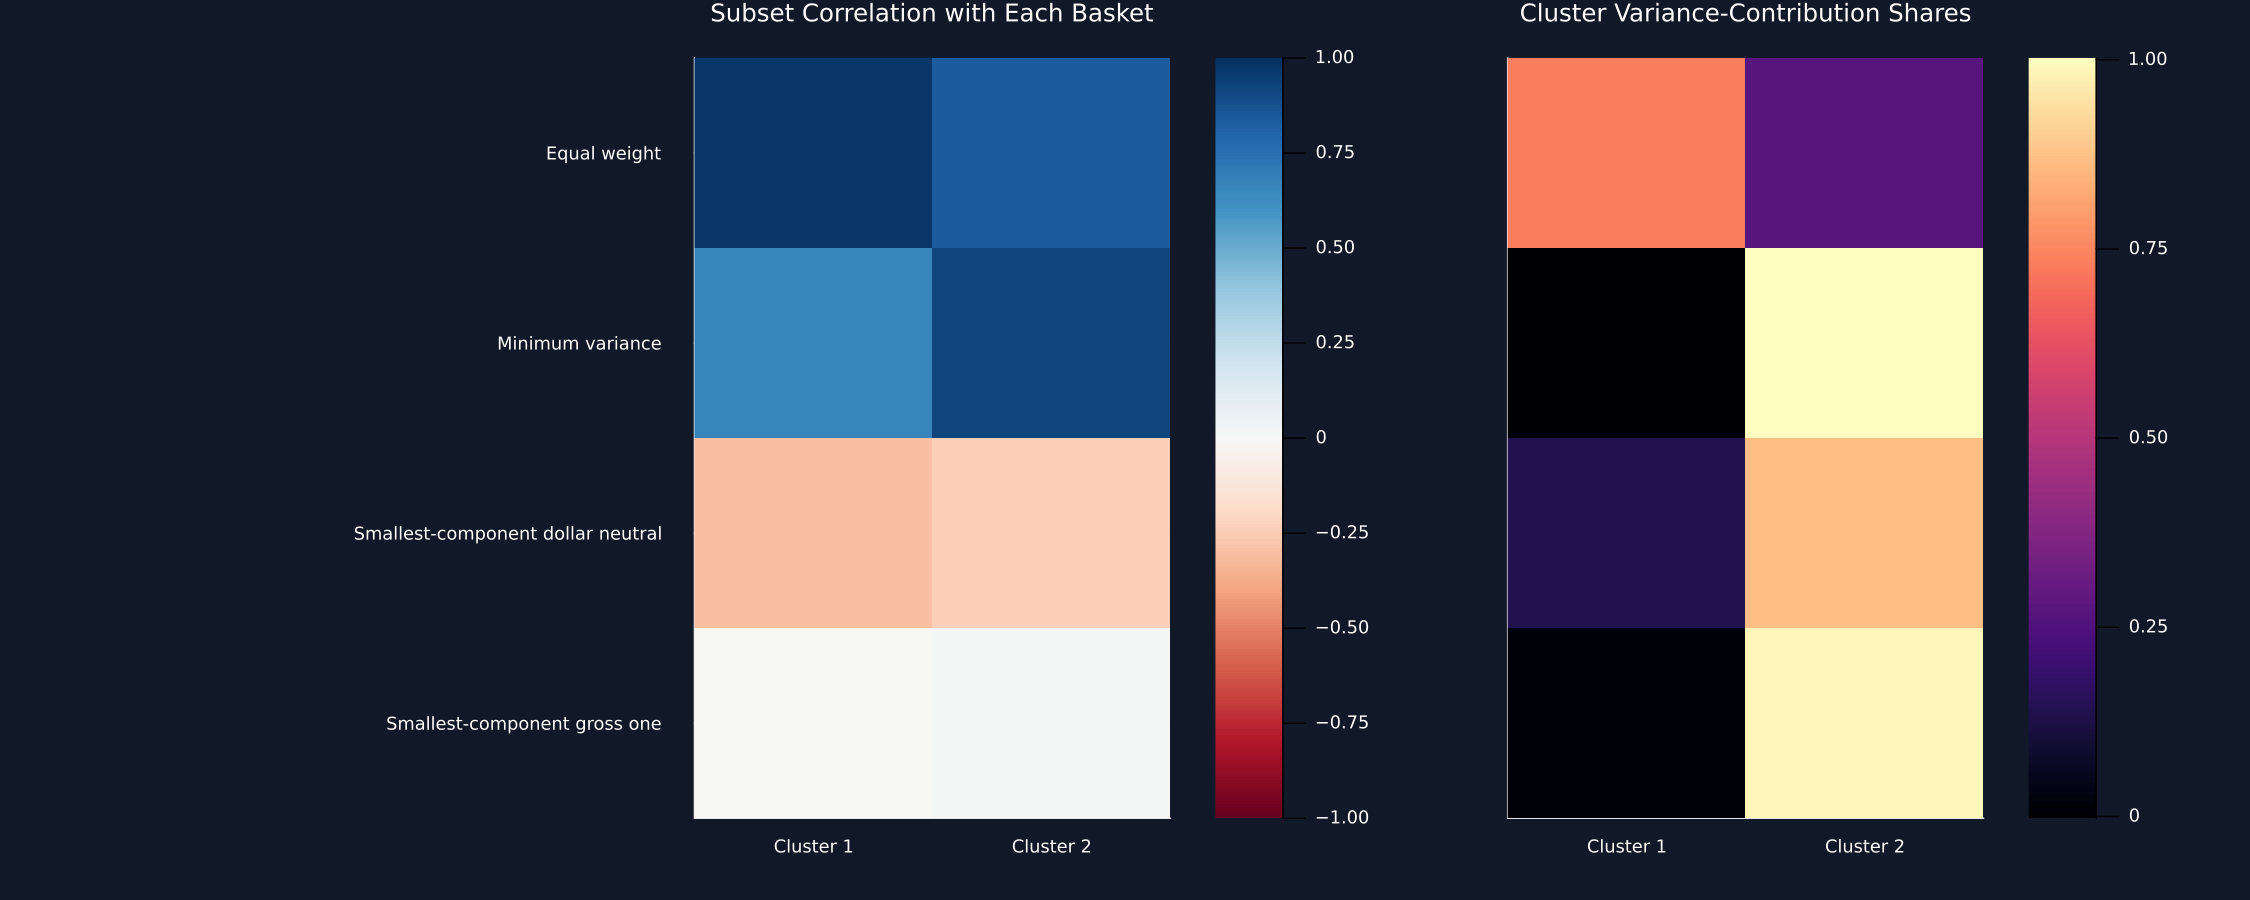

In [5]:
exposure_candidate_rows = NamedTuple[]
function trace_exposure(step,k,features,fitted)
    append!(exposure_candidate_rows,[(step=step,clusters=k,asset=i,label=fitted.labels[i],inertia=fitted.inertia,iterations=fitted.iterations) for i in eachindex(fitted.labels)])
end
_,exposure_clusters,exposure_silhouette = cluster_components(public_correlation,primitive("kmeans_2260.csv");trace=trace_exposure)
save_data(DataFrame(exposure_candidate_rows),paths,"exposure_candidate_fits")
subset_rows = NamedTuple[]
for (name,weights) in diagnostic_baskets
    variance = dot(weights,public_covariance*weights)
    marginal = public_covariance*weights
    for key in sort(collect(keys(exposure_clusters)))
        members = exposure_clusters[key]
        vector = zeros(16)
        vector[members] .= 1/length(members)
        subset_variance = dot(vector,public_covariance*vector)
        correlation = dot(vector,public_covariance*weights)/sqrt(subset_variance*variance)
        contribution = sum(weights[members].*marginal[members])/variance
        push!(subset_rows,(Basket=name,Cluster=key+1,Industries=length(members),correlation=correlation,share=contribution))
    end
end
subset_diagnostics = sort(DataFrame(subset_rows),[:Basket,:Cluster])
rename!(subset_diagnostics,["Basket","Cluster","Industries","Subset correlation","Variance share"])
table(subset_diagnostics,"subset_exposure_diagnostics","Cluster-subset correlation and variance-contribution diagnostics.")
basket_names = sort(first.(diagnostic_baskets))
cluster_count = length(exposure_clusters)
correlation_matrix = reduce(vcat,[permutedims(subset_diagnostics[subset_diagnostics.Basket.==name,"Subset correlation"]) for name in basket_names])
contribution_matrix = reduce(vcat,[permutedims(subset_diagnostics[subset_diagnostics.Basket.==name,"Variance share"]) for name in basket_names])
cluster_labels = ["Cluster "*string(i) for i in 1:cluster_count]
p1 = heatmap(1:cluster_count,1:4,correlation_matrix;color=:RdBu,clims=(-1,1),yflip=true,xticks=(1:cluster_count,cluster_labels),yticks=(1:4,basket_names),tickfontsize=8,left_margin=59Plots.mm,title="Subset Correlation with Each Basket")
p2 = heatmap(1:cluster_count,1:4,contribution_matrix;color=:magma,yflip=true,xticks=(1:cluster_count,cluster_labels),yticks=false,title="Cluster Variance-Contribution Shares")
save_figure(plot(p1,p2;layout=(1,2),size=(1500,600)),paths,"subset_exposure_heatmaps")


## Enforcing hedge position limits

Net exposure, gross exposure, and position bounds constrain different features of a hedge:

$$
E_{\mathrm{net}}=\mathbf 1^{\mathsf T}w,
\qquad
E_{\mathrm{gross}}=\lVert w\rVert_1,
\qquad
\ell_i\leq w_i\leq u_i.
$$

Here, $w$ is the weight vector, $\mathbf 1$ is a vector of ones, $i$ indexes the assets, $E_{\mathrm{net}}$ is long exposure minus short exposure, $E_{\mathrm{gross}}$ is total absolute exposure, and $\ell_i$ and $u_i$ are the lower and upper bounds for asset $i$.

Row,Basket,Net exposure,Gross exposure,Smallest weight,Largest weight,Annual volatility
,String,Float64,Float64,Float64,Float64,Float64
1,Risk-targeted smallest component,0.174582,2.58518,-0.834062,0.966816,0.1
2,Gross-one smallest component,0.0675321,1.0,-0.322632,0.373984,0.0386821
3,Dollar-neutral gross-one hedge,-1.04083e-17,1.0,-0.322414,0.364742,0.0400746


Row,Basket,Industry,Weight
,String,String,Float64
1,Risk-targeted smallest component,Agriculture,-0.0166575
2,Risk-targeted smallest component,Food products,0.966816
3,Risk-targeted smallest component,Soft drinks,0.267421
4,Risk-targeted smallest component,Beer and liquor,-0.834062
5,Risk-targeted smallest component,Tobacco,-0.0788516
6,Risk-targeted smallest component,Recreation,-0.00463396
7,Risk-targeted smallest component,Entertainment,0.0365795
8,Risk-targeted smallest component,Printing and publishing,-0.0509801
9,Risk-targeted smallest component,Household products,-0.0837048


Row,Basket,Gross exposure at most one,Dollar neutral
,String,String,String
1,Risk-targeted smallest component,No,No
2,Gross-one smallest component,Yes,No
3,Dollar-neutral gross-one hedge,Yes,Yes


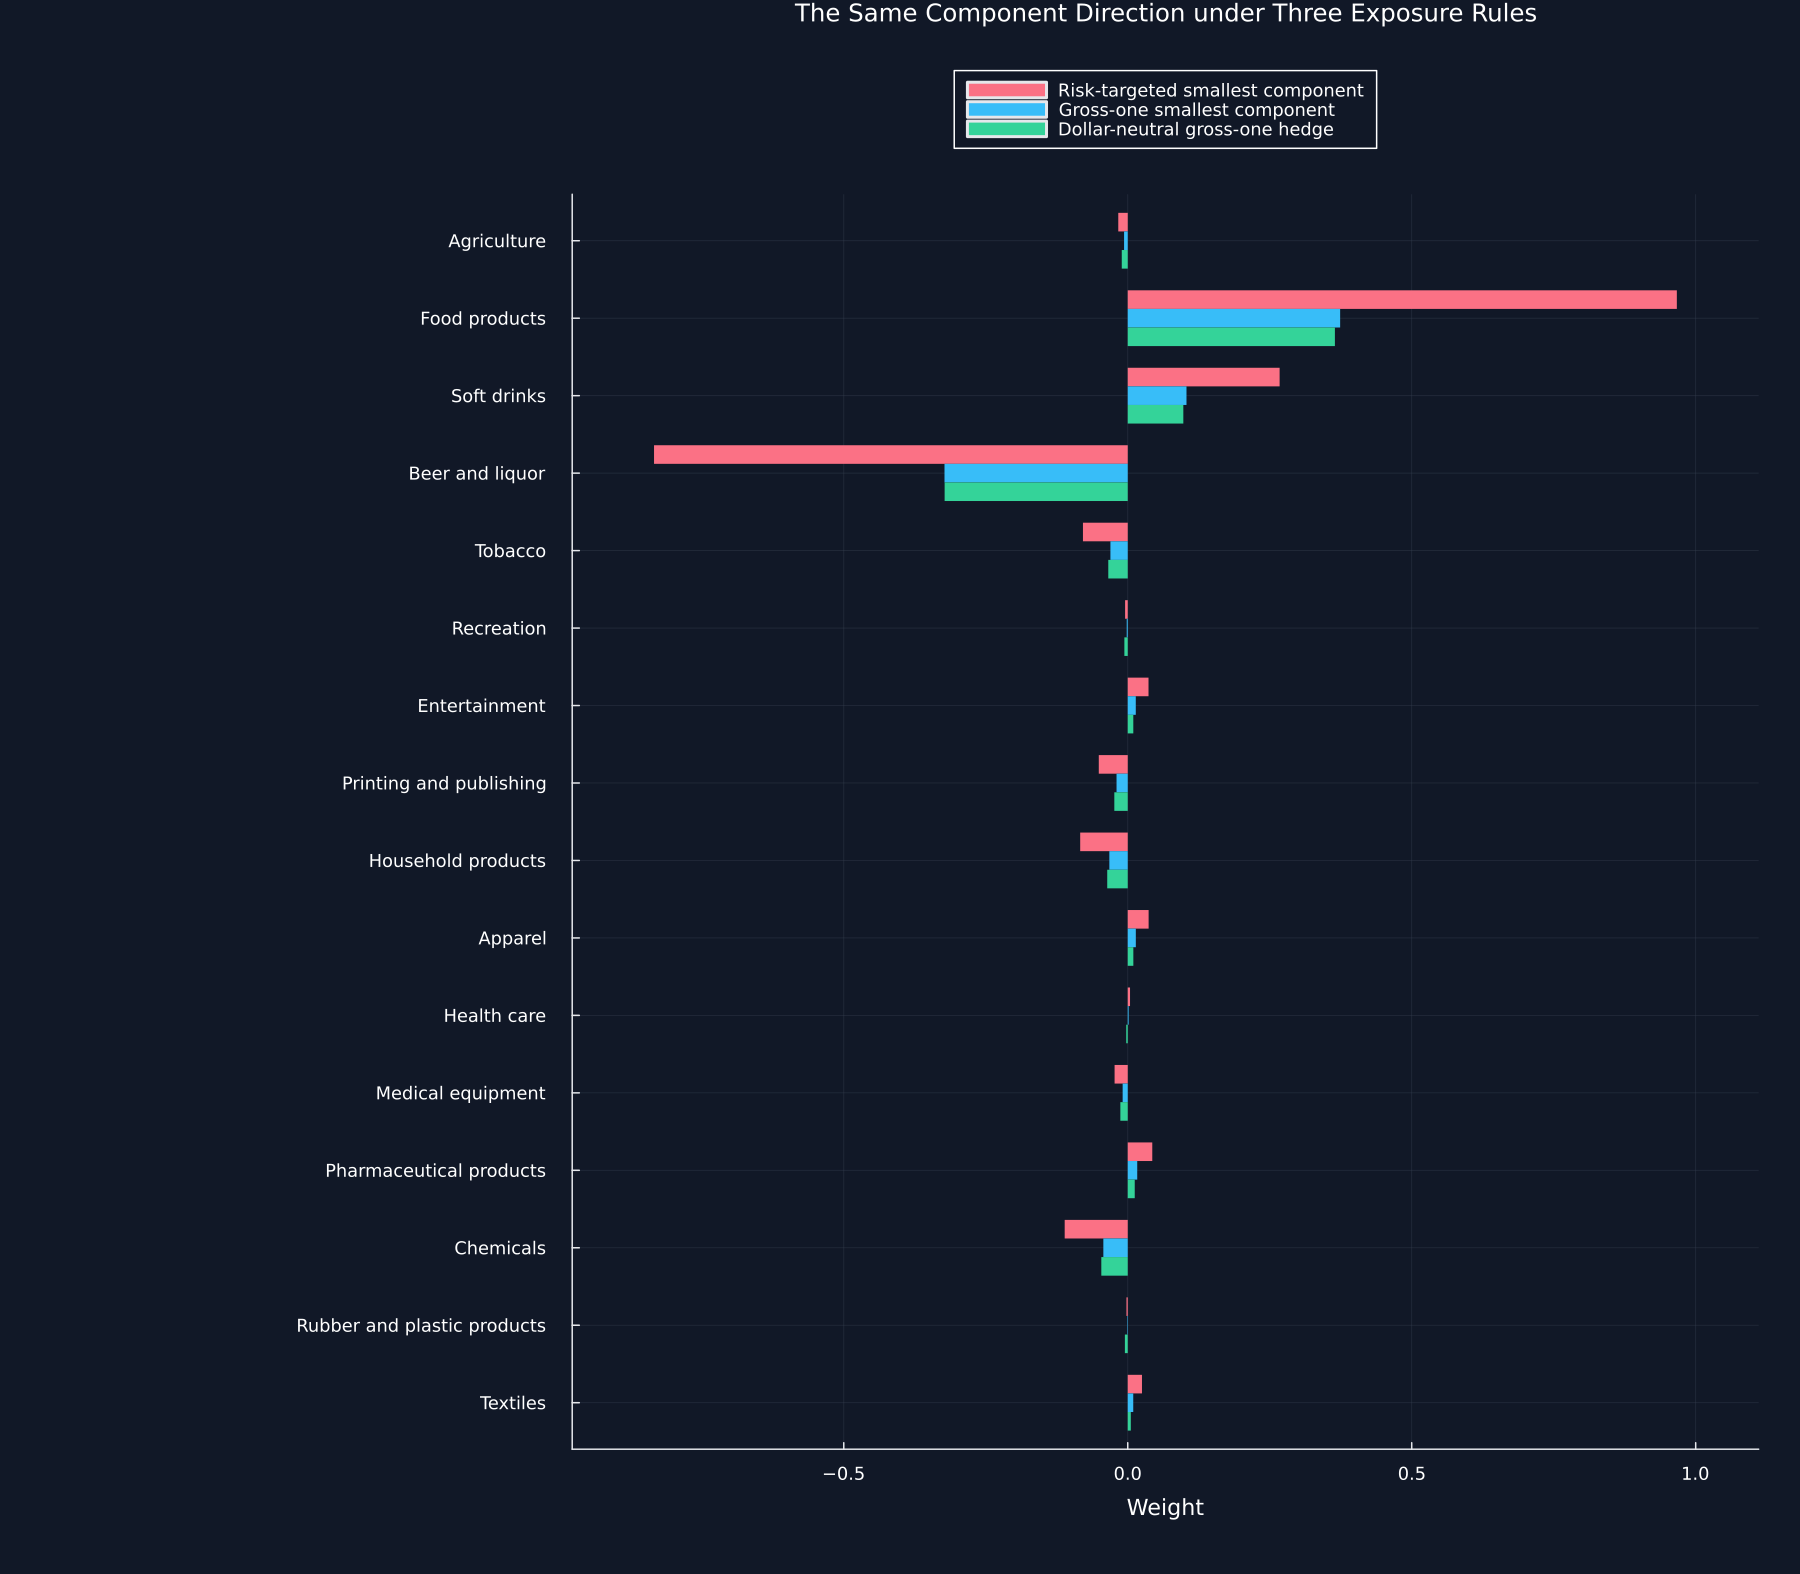

In [6]:
constraint_baskets = ["Risk-targeted smallest component"=>smallest_raw,"Gross-one smallest component"=>smallest_gross,"Dollar-neutral gross-one hedge"=>smallest_neutral]
constraint_rows,constraint_weight_rows = NamedTuple[],NamedTuple[]
for (name,weights) in constraint_baskets
    push!(constraint_rows,(Basket=name,net=sum(weights),gross=sum(abs,weights),smallest=minimum(weights),largest=maximum(weights),volatility=sqrt(dot(weights,public_covariance*weights))))
    append!(constraint_weight_rows,[(Basket=name,Industry=selected_assets[i],Weight=weights[i]) for i in 1:16])
end
constraint_summary = DataFrame(constraint_rows)
rename!(constraint_summary,["Basket","Net exposure","Gross exposure","Smallest weight","Largest weight","Annual volatility"])
constraint_weights = DataFrame(constraint_weight_rows)
table(constraint_summary,"hedge_constraint_summary","Net, gross, position, and volatility diagnostics for three hedge scalings.")
table(constraint_weights,"hedge_constraint_weights","Asset weights under three hedge scalings.")
display(DataFrame("Basket"=>first.(constraint_baskets),"Gross exposure at most one"=>[sum(abs,weights)<=1+1e-12 ? "Yes" : "No" for (_,weights) in constraint_baskets],"Dollar neutral"=>[abs(sum(weights))<=1e-12 ? "Yes" : "No" for (_,weights) in constraint_baskets]))
save_figure(weight_profile(constraint_baskets,[palette.rose,palette.cyan,palette.green],"The Same Component Direction under Three Exposure Rules"),paths,"net_gross_hedge_weights")


## Rolling Stability

Sign alignment separates the arbitrary sign of an eigenvector from a real change in its direction:

$$
\widetilde v_k=\operatorname{sign}(v_{k-1}^{\mathsf T}v_k)v_k,
\qquad
A_k=|v_{k-1}^{\mathsf T}\widetilde v_k|.
$$

Here, $v_k$ is the smallest-eigenvalue loading vector in window $k$, $\widetilde v_k$ is its sign-aligned version, and $A_k$ is the absolute loading alignment, with one indicating identical directions up to sign.

Row,Window,Window end,Smallest eigenvalue,Next eigenvalue,Smallest-eigenvalue gap,Absolute loading alignment,One-way weight change,Net exposure,Gross exposure
,Int64,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,1,2019-12-31,0.00419747,0.00560501,0.00140754,NaN,NaN,0.0311032,1.0
2,2,2020-07-01,0.00740772,0.00751617,0.000108442,0.749529,0.416522,0.0606178,1.0
3,3,2020-12-30,0.00754505,0.0079315,0.000386453,0.814268,0.32726,0.0720443,1.0
4,4,2021-07-01,0.00371372,0.00397519,0.000261465,0.91486,0.279855,0.0499567,1.0
5,5,2021-12-30,0.00330276,0.00357217,0.000269408,0.951486,0.173991,0.0462139,1.0
6,6,2022-07-01,0.00358082,0.0047201,0.00113927,0.920758,0.256298,-0.00691392,1.0
7,7,2022-12-30,0.00384362,0.00521034,0.00136672,0.916276,0.258377,0.0130994,1.0
8,8,2023-07-05,0.00278986,0.0040565,0.00126664,0.952152,0.214382,-0.00482647,1.0
9,9,2024-01-03,0.00281303,0.00344905,0.000636017,0.924119,0.279056,0.0119698,1.0


Row,Quantity,Value
,String,Float64
1,Rolling windows,12.0
2,Mean absolute loading alignment,0.872601
3,Minimum absolute loading alignment,0.583825
4,Mean one-way weight change,0.29278
5,Maximum one-way weight change,0.557026
6,Mean smallest-eigenvalue gap,0.000939391
7,Minimum smallest-eigenvalue gap,0.000108442


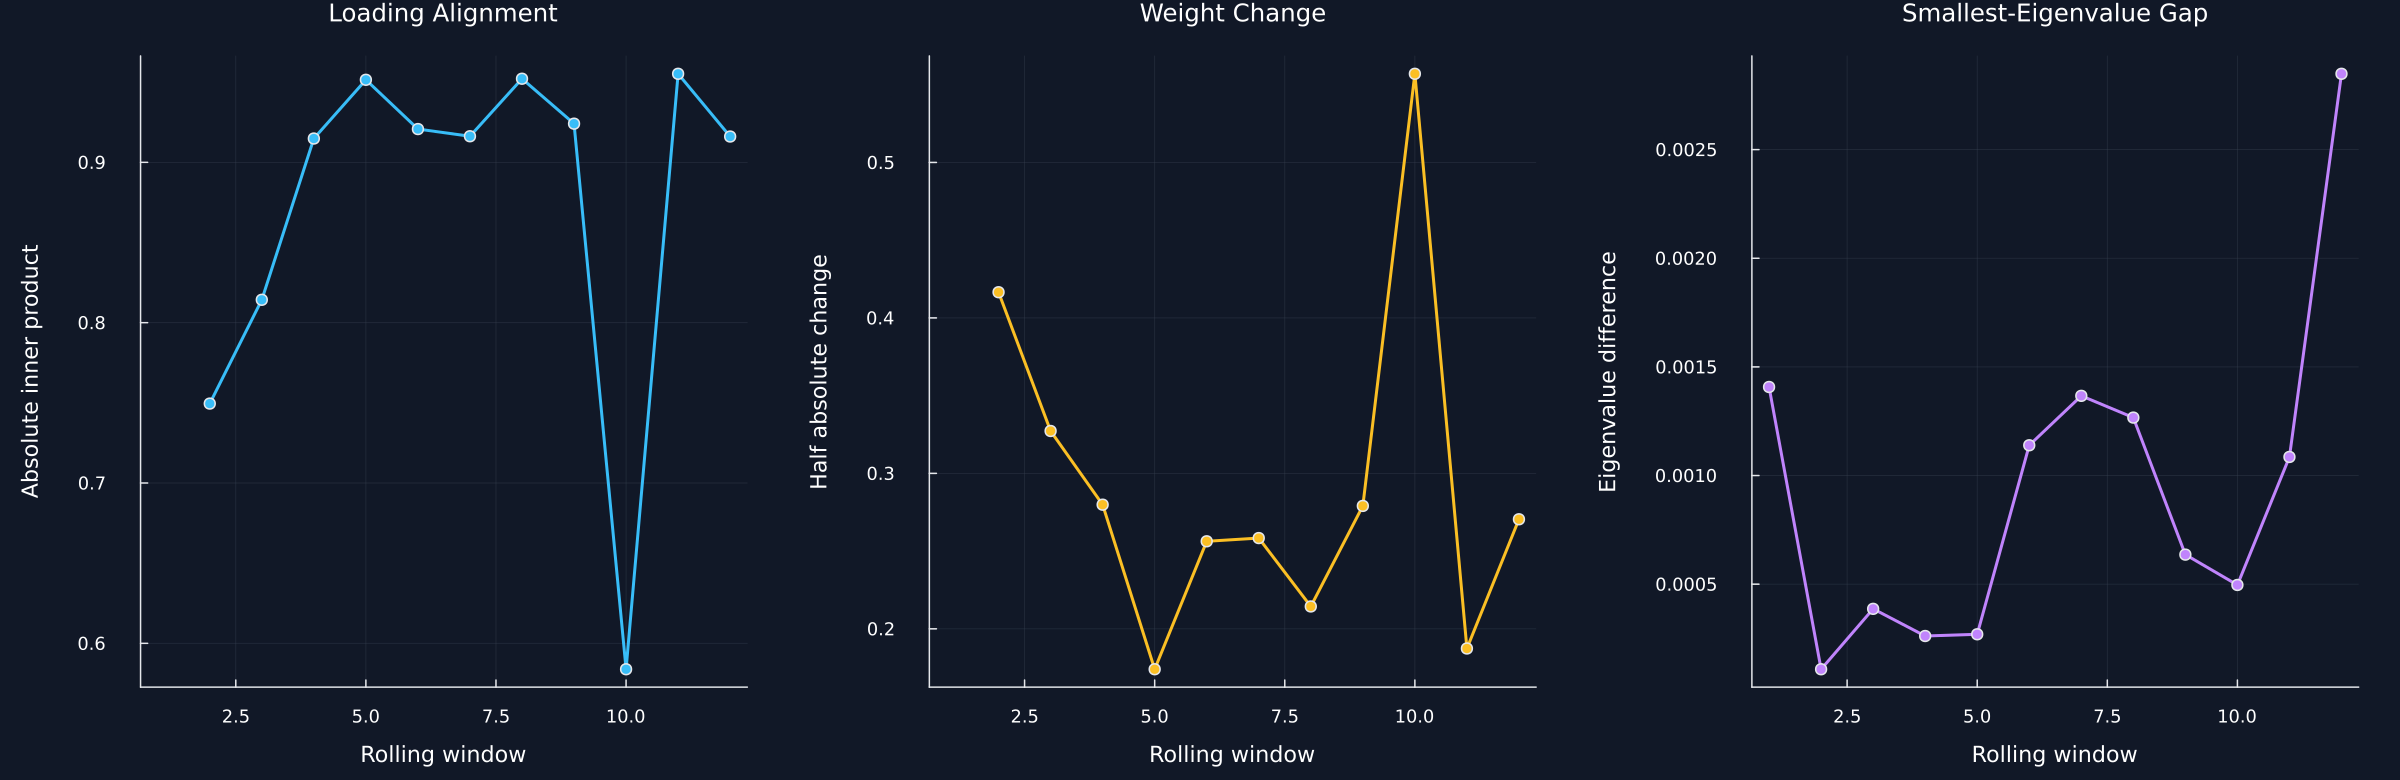

In [7]:
rolling_rows,rolling_weight_rows = NamedTuple[],NamedTuple[]
previous_loading = nothing
previous_weight = nothing
for (window,endpoint) in enumerate(252:126:length(dates))
    covariance = cov(public_sample[endpoint-251:endpoint,:])*252
    factor = eigen(Symmetric(covariance,:L);alg=LinearAlgebra.DivideAndConquer())
    loading = factor.vectors[:,1]
    if !isnothing(previous_loading) && dot(previous_loading,loading)<0
        loading = -loading
    end
    weight = loading/sum(abs,loading)
    alignment = isnothing(previous_loading) ? NaN : abs(dot(previous_loading,loading))
    change = isnothing(previous_weight) ? NaN : turnover(weight,previous_weight)
    push!(rolling_rows,(window=window,date=string(dates[endpoint]),smallest=factor.values[1],next=factor.values[2],gap=factor.values[2]-factor.values[1],alignment=alignment,change=change,net=sum(weight),gross=sum(abs,weight)))
    append!(rolling_weight_rows,[(window=window,asset=i,loading=loading[i],weight=weight[i]) for i in 1:16])
    previous_loading,previous_weight = loading,weight
end
rolling_hedge = DataFrame(rolling_rows)
rename!(rolling_hedge,["Window","Window end","Smallest eigenvalue","Next eigenvalue","Smallest-eigenvalue gap","Absolute loading alignment","One-way weight change","Net exposure","Gross exposure"])
alignments = filter(isfinite,rolling_hedge[!,"Absolute loading alignment"])
changes = filter(isfinite,rolling_hedge[!,"One-way weight change"])
gaps = rolling_hedge[!,"Smallest-eigenvalue gap"]
rolling_hedge_summary = DataFrame("Quantity"=>["Rolling windows","Mean absolute loading alignment","Minimum absolute loading alignment","Mean one-way weight change","Maximum one-way weight change","Mean smallest-eigenvalue gap","Minimum smallest-eigenvalue gap"],"Value"=>[nrow(rolling_hedge),mean(alignments),minimum(alignments),mean(changes),maximum(changes),mean(gaps),minimum(gaps)])
table(rolling_hedge,"rolling_pca_hedge_stability","Rolling public smallest-component hedge diagnostics.")
table(rolling_hedge_summary,"rolling_pca_hedge_summary","Summary of rolling public hedge stability.")
panels = [plot(rolling_hedge.Window,rolling_hedge[!,column];color,marker=:circle,title,xlabel="Rolling window",ylabel,legend=false) for (column,color,title,ylabel) in [("Absolute loading alignment",palette.cyan,"Loading Alignment","Absolute inner product"),("One-way weight change",palette.amber,"Weight Change","Half absolute change"),("Smallest-eigenvalue gap",violet,"Smallest-Eigenvalue Gap","Eigenvalue difference")]]
save_figure(plot(panels...;layout=(1,3),size=(1600,520)),paths,"rolling_pca_hedge_stability")
save_data(DataFrame(rolling_weight_rows),paths,"rolling_hedge_weights")
nothing


## Calculation Checks

When the component-risk shares sum to one, the implemented scaling gives the requested variance exactly up to numerical precision:

$$
w^{\mathsf T}\Sigma w=s^2\sum_{k=1}^{N}\rho_k=s^2.
$$

Here, $w$ is the principal-component weight vector, $s$ is the requested standard deviation, $\rho_k$ is the risk share of component $k$, $N$ is the number of components, and $\Sigma$ is the covariance matrix.

In [8]:
test_covariance = [1.0 1.0;1.0 4.0]
default_test_weights = pca_weights(test_covariance;risk_target=1.0)
explicit_test_weights = pca_weights(test_covariance;risk_distribution=[0.0,1.0],risk_target=1.0)
public_direct_weights = last(pca_baskets[end])
public_library_weights = last(library_pca_baskets[end])
direction_difference = min(maximum(abs,public_direct_weights-public_library_weights),maximum(abs,public_direct_weights+public_library_weights))
released_checks = DataFrame("Check"=>["Two-asset default variance","Two-asset explicit smallest-component variance","Default and explicit weight difference","Public direct and library direction difference","Public requested variance","Public realized variance"],"Value"=>[dot(default_test_weights,test_covariance*default_test_weights),dot(explicit_test_weights,test_covariance*explicit_test_weights),maximum(abs,default_test_weights-explicit_test_weights),direction_difference,target_standard_deviation^2,dot(public_direct_weights,public_covariance*public_direct_weights)])
preliminary_hedging_parity = DataFrame("Preliminary or library item"=>["PCA minimum-variance component weights","Alternative component-risk distribution","Target-variance identity","Two-asset calculation check","Asset contribution to risk","Asset correlation to basket","Subset correlation to basket","Net and gross exposure checks","Rolling loading stability"],"Chapter 22 location"=>fill("Section 22.3",9),"Status"=>fill("Included",9))
hedging_section_summary = DataFrame("Quantity"=>["Public observations","Selected industries","Principal components","Risk distributions","Diagnostic baskets","Detected exposure clusters","Rolling hedge windows"],"Value"=>[length(dates),16,component_count,length(risk_distributions),length(diagnostic_baskets),length(exposure_clusters),nrow(rolling_hedge)])
table(released_checks,"released_pca_weight_checks","Direct checks of the principal-component weight calculation.")
table(preliminary_hedging_parity,"preliminary_hedging_parity","Coverage of hedge calculations and diagnostics.")
table(hedging_section_summary,"hedging_section_summary","Section 22.3 numerical summary.")


Row,Check,Value
,String,Float64
1,Two-asset default variance,1.0
2,Two-asset explicit smallest-component variance,1.0
3,Default and explicit weight difference,0.0
4,Public direct and library direction difference,1.95399e-14
5,Public requested variance,0.01
6,Public realized variance,0.01


Row,Preliminary or library item,Chapter 22 location,Status
,String,String,String
1,PCA minimum-variance component weights,Section 22.3,Included
2,Alternative component-risk distribution,Section 22.3,Included
3,Target-variance identity,Section 22.3,Included
4,Two-asset calculation check,Section 22.3,Included
5,Asset contribution to risk,Section 22.3,Included
6,Asset correlation to basket,Section 22.3,Included
7,Subset correlation to basket,Section 22.3,Included
8,Net and gross exposure checks,Section 22.3,Included
9,Rolling loading stability,Section 22.3,Included


Row,Quantity,Value
,String,Int64
1,Public observations,1760
2,Selected industries,16
3,Principal components,16
4,Risk distributions,3
5,Diagnostic baskets,4
6,Detected exposure clusters,2
7,Rolling hedge windows,12


## Tests

In [9]:
@assert size(public_sample)==(1760,16)
@assert all(eigenvalues.>0)
@assert all(diff(eigenvalues).<=0)
@assert sum(explained_variance)≈1
@assert last(cumulative_variance)≈1
@assert Set(first.(pca_baskets))==Set(["Leading component","Equal component risk","Smallest component"])
@assert pca_target_summary[!,"Realized standard deviation"]≈fill(target_standard_deviation,3)
@assert pca_target_summary[[1,3],"Largest component variance share"]≈ones(2)
@assert nrow(pca_weight_table)==3component_count
@assert nrow(component_risk)==3component_count
@assert all(sum(group[!,"Variance share"])≈1 for group in groupby(component_risk,:Basket))
@assert nrow(basket_diagnostics)==4
@assert nrow(asset_diagnostics)==4component_count
@assert all(sum(group[!,"Variance-contribution share"])≈1 for group in groupby(asset_diagnostics,:Basket))
@assert all(abs.(asset_diagnostics[!,"Correlation to basket"]).<=1+1e-12)
@assert 2<=length(exposure_clusters)<=4
@assert nrow(subset_diagnostics)==length(diagnostic_baskets)*length(exposure_clusters)
@assert all(abs.(subset_diagnostics[!,"Subset correlation"]).<=1+1e-12)
@assert all(sum(group[!,"Variance share"])≈1 for group in groupby(subset_diagnostics,:Basket))
@assert sum(abs,smallest_gross)≈1
@assert sum(abs,smallest_neutral)≈1
@assert abs(sum(smallest_neutral))<1e-12
@assert nrow(constraint_summary)==3
@assert nrow(rolling_hedge)>=10
@assert all(0 .<=alignments.<=1+1e-12)
@assert all(changes.>=0)
@assert all(gaps.>0)
@assert rolling_hedge[!,"Gross exposure"]≈ones(nrow(rolling_hedge))
@assert dot(default_test_weights,test_covariance*default_test_weights)≈1
@assert dot(explicit_test_weights,test_covariance*explicit_test_weights)≈1
@assert default_test_weights≈explicit_test_weights
@assert released_checks.Value[3]<1e-12
@assert released_checks.Value[4]<1e-12
@assert released_checks.Value[5]≈released_checks.Value[6]
@assert nrow(preliminary_hedging_parity)==9
@assert all(preliminary_hedging_parity.Status.=="Included")
@assert nrow(hedging_section_summary)==7
@assert isfile(joinpath(paths.figures,"public_pca_spectrum_loadings.pdf"))
@assert isfile(joinpath(paths.figures,"pca_weight_profiles.pdf"))
@assert isfile(joinpath(paths.figures,"pca_component_exposures.pdf"))
@assert isfile(joinpath(paths.figures,"basket_risk_and_correlation.pdf"))
@assert isfile(joinpath(paths.figures,"subset_exposure_heatmaps.pdf"))
@assert isfile(joinpath(paths.figures,"net_gross_hedge_weights.pdf"))
@assert isfile(joinpath(paths.figures,"rolling_pca_hedge_stability.pdf"))
@assert isfile(joinpath(paths.tables,"released_pca_weight_checks.tex"))
